# 05 — BRISC Preprocessing

This notebook defines and verifies the reproducible preprocessing pipeline for
the BRISC 2025 classification and segmentation tasks.

The preprocessing workflow uses the fixed leakage-controlled classification
manifests produced in Notebook 4. No new train/validation split is created in
this notebook.

## Objectives

1. Load and verify the definitive classification train, validation, and test
   manifests.
2. Define consistent image loading and channel handling.
3. Examine resizing requirements while preserving anatomical content.
4. Establish deterministic classification preprocessing independently of any
   final model architecture.
5. Define segmentation MRI and mask preprocessing.
6. Convert segmentation masks to binary form using the previously validated
   threshold of 128.
7. Ensure MRI and mask spatial transformations remain synchronized.
8. Separate deterministic preprocessing from training-only data augmentation.
9. Visually and numerically verify preprocessing outputs.
10. Save preprocessing configuration and metadata for downstream model
    development.

No model training is performed in this notebook.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\HP\Documents\Projects\Brain_Tumor_XAI"
)

DATASET_ROOT = (
    PROJECT_ROOT /
    "data" /
    "raw" /
    "brisc2025"
)

PROCESSED_ROOT = (
    PROJECT_ROOT /
    "data" /
    "processed"
)

OUTPUTS_ROOT = (
    PROJECT_ROOT /
    "outputs"
)

TABLES_ROOT = (
    OUTPUTS_ROOT /
    "tables"
)

FIGURES_ROOT = (
    OUTPUTS_ROOT /
    "figures"
)

TABLES_ROOT.mkdir(parents=True, exist_ok=True)
FIGURES_ROOT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Fixed classification manifests from Notebook 4
# ------------------------------------------------------------

TRAIN_MANIFEST_PATH = (
    PROCESSED_ROOT /
    "classification_train_manifest.csv"
)

VALIDATION_MANIFEST_PATH = (
    PROCESSED_ROOT /
    "classification_validation_manifest.csv"
)

TEST_MANIFEST_PATH = (
    PROCESSED_ROOT /
    "classification_test_manifest.csv"
)

MASTER_SPLIT_PATH = (
    PROCESSED_ROOT /
    "classification_final_split_manifest.csv"
)

# Raw BRISC manifest for segmentation metadata
RAW_MANIFEST_PATH = (
    DATASET_ROOT /
    "manifest.csv"
)

# ------------------------------------------------------------
# Load manifests
# ------------------------------------------------------------

train_df = pd.read_csv(TRAIN_MANIFEST_PATH)
validation_df = pd.read_csv(VALIDATION_MANIFEST_PATH)
test_df = pd.read_csv(TEST_MANIFEST_PATH)
master_split_df = pd.read_csv(MASTER_SPLIT_PATH)

manifest_df = pd.read_csv(RAW_MANIFEST_PATH)

# ------------------------------------------------------------
# Basic verification
# ------------------------------------------------------------

print("CLASSIFICATION MANIFESTS")
print("-" * 70)

print("Train records:", len(train_df))
print("Validation records:", len(validation_df))
print("Test records:", len(test_df))
print("Master split records:", len(master_split_df))

print("\nFiles found:")
print("Train manifest:", TRAIN_MANIFEST_PATH.exists())
print("Validation manifest:", VALIDATION_MANIFEST_PATH.exists())
print("Test manifest:", TEST_MANIFEST_PATH.exists())
print("Master manifest:", MASTER_SPLIT_PATH.exists())
print("Raw BRISC manifest:", RAW_MANIFEST_PATH.exists())

# ------------------------------------------------------------
# Segmentation subsets
# ------------------------------------------------------------

segmentation_mri_df = manifest_df[
    (manifest_df["task"] == "segmentation") &
    (manifest_df["is_mask"] == False)
].copy().reset_index(drop=True)

segmentation_mask_df = manifest_df[
    (manifest_df["task"] == "segmentation") &
    (manifest_df["is_mask"] == True)
].copy().reset_index(drop=True)

print("\nSEGMENTATION MANIFEST")
print("-" * 70)

print("MRI records:", len(segmentation_mri_df))
print("Mask records:", len(segmentation_mask_df))

CLASSIFICATION MANIFESTS
----------------------------------------------------------------------
Train records: 3889
Validation records: 973
Test records: 1000
Master split records: 5862

Files found:
Train manifest: True
Validation manifest: True
Test manifest: True
Master manifest: True
Raw BRISC manifest: True

SEGMENTATION MANIFEST
----------------------------------------------------------------------
MRI records: 4793
Mask records: 4793


## 1. Fixed Split Verification

The classification subsets used in this notebook must exactly match the
leakage-controlled manifests exported by Notebook 4.

No random splitting or reassignment is performed during preprocessing.
The following checks verify split membership, uniqueness, and consistency with
the combined master split manifest.

In [2]:
# ------------------------------------------------------------
# Verify fixed classification split integrity
# ------------------------------------------------------------

print("FIXED CLASSIFICATION SPLIT VERIFICATION")
print("-" * 70)

# Expected sizes
assert len(train_df) == 3889
assert len(validation_df) == 973
assert len(test_df) == 1000
assert len(master_split_df) == 5862

print("Expected split sizes: PASSED")


# ------------------------------------------------------------
# Verify model_split labels
# ------------------------------------------------------------

print("\nMODEL SPLIT LABELS")
print("-" * 70)

print(
    "Train labels:",
    sorted(train_df["model_split"].unique())
)

print(
    "Validation labels:",
    sorted(validation_df["model_split"].unique())
)

print(
    "Test labels:",
    sorted(test_df["model_split"].unique())
)

assert set(train_df["model_split"]) == {"train"}
assert set(validation_df["model_split"]) == {"validation"}
assert set(test_df["model_split"]) == {"test"}

print("Model split labels: PASSED")


# ------------------------------------------------------------
# Verify individual manifests exactly match master membership
# ------------------------------------------------------------

master_train_paths = set(
    master_split_df.loc[
        master_split_df["model_split"] == "train",
        "relative_path"
    ]
)

master_validation_paths = set(
    master_split_df.loc[
        master_split_df["model_split"] == "validation",
        "relative_path"
    ]
)

master_test_paths = set(
    master_split_df.loc[
        master_split_df["model_split"] == "test",
        "relative_path"
    ]
)

train_paths = set(train_df["relative_path"])
validation_paths = set(validation_df["relative_path"])
test_paths = set(test_df["relative_path"])

print("\nMASTER-MANIFEST MEMBERSHIP")
print("-" * 70)

print(
    "Train matches master:",
    train_paths == master_train_paths
)

print(
    "Validation matches master:",
    validation_paths == master_validation_paths
)

print(
    "Test matches master:",
    test_paths == master_test_paths
)

assert train_paths == master_train_paths
assert validation_paths == master_validation_paths
assert test_paths == master_test_paths


# ------------------------------------------------------------
# Verify there is no path overlap
# ------------------------------------------------------------

print("\nPATH OVERLAP")
print("-" * 70)

print(
    "Train ↔ Validation:",
    len(train_paths & validation_paths)
)

print(
    "Train ↔ Test:",
    len(train_paths & test_paths)
)

print(
    "Validation ↔ Test:",
    len(validation_paths & test_paths)
)

assert len(train_paths & validation_paths) == 0
assert len(train_paths & test_paths) == 0
assert len(validation_paths & test_paths) == 0


# ------------------------------------------------------------
# Verify decoded-content fingerprint overlap
# ------------------------------------------------------------

train_fp = set(train_df["decoded_rgb_sha256"])
validation_fp = set(validation_df["decoded_rgb_sha256"])
test_fp = set(test_df["decoded_rgb_sha256"])

print("\nDECODED-CONTENT OVERLAP")
print("-" * 70)

print(
    "Train ↔ Validation:",
    len(train_fp & validation_fp)
)

print(
    "Train ↔ Test:",
    len(train_fp & test_fp)
)

print(
    "Validation ↔ Test:",
    len(validation_fp & test_fp)
)

assert len(train_fp & validation_fp) == 0
assert len(train_fp & test_fp) == 0
assert len(validation_fp & test_fp) == 0


# ------------------------------------------------------------
# Verify each development image is content-unique
# ------------------------------------------------------------

print("\nWITHIN-SPLIT DUPLICATES")
print("-" * 70)

print(
    "Train duplicate fingerprints:",
    len(train_df) - train_df["decoded_rgb_sha256"].nunique()
)

print(
    "Validation duplicate fingerprints:",
    len(validation_df)
    - validation_df["decoded_rgb_sha256"].nunique()
)

assert train_df["decoded_rgb_sha256"].nunique() == len(train_df)
assert (
    validation_df["decoded_rgb_sha256"].nunique()
    == len(validation_df)
)

print("\nAll fixed split verification checks PASSED.")

FIXED CLASSIFICATION SPLIT VERIFICATION
----------------------------------------------------------------------
Expected split sizes: PASSED

MODEL SPLIT LABELS
----------------------------------------------------------------------
Train labels: ['train']
Validation labels: ['validation']
Test labels: ['test']
Model split labels: PASSED

MASTER-MANIFEST MEMBERSHIP
----------------------------------------------------------------------
Train matches master: True
Validation matches master: True
Test matches master: True

PATH OVERLAP
----------------------------------------------------------------------
Train ↔ Validation: 0
Train ↔ Test: 0
Validation ↔ Test: 0

DECODED-CONTENT OVERLAP
----------------------------------------------------------------------
Train ↔ Validation: 0
Train ↔ Test: 0
Validation ↔ Test: 0

WITHIN-SPLIT DUPLICATES
----------------------------------------------------------------------
Train duplicate fingerprints: 0
Validation duplicate fingerprints: 0

All fixed spl

## 2. Classification Image Geometry and Channel Audit

Before defining image preprocessing, the fixed classification splits are audited
for native dimensions, aspect ratios, and image modes.

This step is necessary because BRISC contains images with heterogeneous native
resolutions and both grayscale and RGB encodings.

The resize and channel-standardization strategy will be selected only after the
retained training, validation, and test images have been characterized.

In [3]:
# ------------------------------------------------------------
# Audit native dimensions and image modes
# for all retained classification records
# ------------------------------------------------------------

classification_geometry_records = []

print("Scanning retained classification images...")
print(
    "Images to inspect:",
    len(master_split_df)
)

for i, row in master_split_df.iterrows():

    image_path = (
        DATASET_ROOT /
        Path(row["relative_path"])
    )

    with Image.open(image_path) as img:
        width, height = img.size
        mode = img.mode

    classification_geometry_records.append({
        "filename": row["filename"],
        "model_split": row["model_split"],
        "tumor_label": row["tumor_label"],
        "plane_label": row["plane_label"],
        "width": width,
        "height": height,
        "mode": mode,
        "aspect_ratio": width / height,
        "is_square": width == height
    })

    if (i + 1) % 500 == 0:
        print(
            f"Processed {i + 1}/{len(master_split_df)}"
        )


classification_geometry_df = pd.DataFrame(
    classification_geometry_records
)

print("\nScan complete.")
print(
    "Images inspected:",
    len(classification_geometry_df)
)

print(
    "Unique native dimensions:",
    classification_geometry_df[
        ["width", "height"]
    ]
    .drop_duplicates()
    .shape[0]
)

print(
    "Unique image modes:",
    sorted(
        classification_geometry_df[
            "mode"
        ].unique()
    )
)

Scanning retained classification images...
Images to inspect: 5862
Processed 500/5862
Processed 1000/5862
Processed 1500/5862
Processed 2000/5862
Processed 2500/5862
Processed 3000/5862
Processed 3500/5862
Processed 4000/5862
Processed 4500/5862
Processed 5000/5862
Processed 5500/5862

Scan complete.
Images inspected: 5862
Unique native dimensions: 183
Unique image modes: ['L', 'RGB']


In [4]:
print("CLASSIFICATION IMAGE GEOMETRY SUMMARY")
print("-" * 70)

print(
    "Total retained images:",
    len(classification_geometry_df)
)

print(
    "Square images:",
    int(
        classification_geometry_df[
            "is_square"
        ].sum()
    )
)

print(
    "Non-square images:",
    int(
        (~classification_geometry_df[
            "is_square"
        ]).sum()
    )
)

print(
    "Square percentage:",
    round(
        100 *
        classification_geometry_df[
            "is_square"
        ].mean(),
        2
    ),
    "%"
)


print("\nIMAGE MODES")
print("-" * 70)

display(
    classification_geometry_df[
        "mode"
    ]
    .value_counts()
    .rename("records")
    .to_frame()
)


print("\nMOST COMMON DIMENSIONS")
print("-" * 70)

dimension_counts = (
    classification_geometry_df
    .groupby(
        ["width", "height"]
    )
    .size()
    .sort_values(
        ascending=False
    )
    .rename("records")
)

display(
    dimension_counts.head(15).to_frame()
)


print("\nASPECT-RATIO SUMMARY")
print("-" * 70)

display(
    classification_geometry_df[
        "aspect_ratio"
    ]
    .describe()
    .round(4)
    .to_frame()
)


print("\nMODE BY MODEL SPLIT")
print("-" * 70)

display(
    pd.crosstab(
        classification_geometry_df[
            "model_split"
        ],
        classification_geometry_df[
            "mode"
        ]
    )
)

CLASSIFICATION IMAGE GEOMETRY SUMMARY
----------------------------------------------------------------------
Total retained images: 5862
Square images: 5289
Non-square images: 573
Square percentage: 90.23 %

IMAGE MODES
----------------------------------------------------------------------


,records
mode,
RGB,3001
L,2861



MOST COMMON DIMENSIONS
----------------------------------------------------------------------


,,records
width,height,
512,512,4851
369,369,363
216,369,354
256,256,30
187,369,21
202,369,19
210,369,12
225,225,12
236,236,8



ASPECT-RATIO SUMMARY
----------------------------------------------------------------------


,aspect_ratio
count,5862.0000
mean,0.9697
std,0.1104
min,0.5068
25%,1.0000
50%,1.0000
75%,1.0000
max,1.6103



MODE BY MODEL SPLIT
----------------------------------------------------------------------


mode,L,RGB
model_split,,
test,582,418
train,1822,2067
validation,457,516


## 2.1 Geometry Distribution Across Classes and Splits

Because aspect-ratio-preserving resizing may introduce padding for non-square
images, native geometry is examined by tumor class and dataset split.

This check helps determine whether non-square image geometry is strongly
associated with a particular class or subset, which could otherwise introduce
a source-related visual cue during model training.

In [5]:
# ------------------------------------------------------------
# Audit non-square image distribution by class and split
# ------------------------------------------------------------

geometry_class_summary = (
    classification_geometry_df
    .groupby("tumor_label")
    .agg(
        total_images=("filename", "size"),
        square_images=("is_square", "sum")
    )
)

geometry_class_summary["non_square_images"] = (
    geometry_class_summary["total_images"]
    - geometry_class_summary["square_images"]
)

geometry_class_summary["non_square_percent"] = (
    100
    * geometry_class_summary["non_square_images"]
    / geometry_class_summary["total_images"]
)

print("NON-SQUARE IMAGES BY CLASS")
print("-" * 70)

display(
    geometry_class_summary.round(2)
)


geometry_split_summary = (
    classification_geometry_df
    .groupby("model_split")
    .agg(
        total_images=("filename", "size"),
        square_images=("is_square", "sum")
    )
)

geometry_split_summary["non_square_images"] = (
    geometry_split_summary["total_images"]
    - geometry_split_summary["square_images"]
)

geometry_split_summary["non_square_percent"] = (
    100
    * geometry_split_summary["non_square_images"]
    / geometry_split_summary["total_images"]
)

print("\nNON-SQUARE IMAGES BY MODEL SPLIT")
print("-" * 70)

display(
    geometry_split_summary.round(2)
)


print("\nNON-SQUARE IMAGES — CLASS × SPLIT")
print("-" * 70)

non_square_class_split = pd.crosstab(
    classification_geometry_df.loc[
        ~classification_geometry_df["is_square"],
        "tumor_label"
    ],
    classification_geometry_df.loc[
        ~classification_geometry_df["is_square"],
        "model_split"
    ]
)

display(non_square_class_split)

NON-SQUARE IMAGES BY CLASS
----------------------------------------------------------------------


,total_images,square_images,non_square_images,non_square_percent
tumor_label,,,,
glioma,1401,1401,0,0.00
meningioma,1523,1396,127,8.34
no_tumor,1198,759,439,36.64
pituitary,1740,1733,7,0.40



NON-SQUARE IMAGES BY MODEL SPLIT
----------------------------------------------------------------------


,total_images,square_images,non_square_images,non_square_percent
model_split,,,,
test,1000,824,176,17.60
train,3889,3582,307,7.89
validation,973,883,90,9.25



NON-SQUARE IMAGES — CLASS × SPLIT
----------------------------------------------------------------------


model_split,test,train,validation
tumor_label,,,
meningioma,99,22,6
no_tumor,77,279,83
pituitary,0,6,1


## 2.2 RGB Channel-Content Audit

BRISC contains both grayscale (`L`) and RGB-encoded MRI files.

Because MRI intensity images are fundamentally grayscale, RGB files are examined
to determine whether their three channels contain meaningful channel-specific
information or primarily represent grayscale imagery stored using RGB encoding.

The channel-standardization policy will be selected only after this audit.

In [6]:
# ------------------------------------------------------------
# Audit RGB channel differences
# ------------------------------------------------------------

rgb_manifest_df = (
    master_split_df[
        master_split_df["filename"].isin(
            classification_geometry_df.loc[
                classification_geometry_df["mode"] == "RGB",
                "filename"
            ]
        )
    ]
    .copy()
    .reset_index(drop=True)
)

rgb_channel_records = []

print("Auditing RGB channel content...")
print("RGB images to inspect:", len(rgb_manifest_df))

for i, row in rgb_manifest_df.iterrows():

    image_path = (
        DATASET_ROOT /
        Path(row["relative_path"])
    )

    with Image.open(image_path) as img:
        rgb_arr = np.asarray(
            img.convert("RGB"),
            dtype=np.uint8
        )

    # Pixel-wise spread between largest and smallest channel
    channel_spread = (
        rgb_arr.max(axis=2).astype(np.int16)
        -
        rgb_arr.min(axis=2).astype(np.int16)
    )

    rgb_channel_records.append({
        "filename": row["filename"],
        "model_split": row["model_split"],
        "tumor_label": row["tumor_label"],
        "plane_label": row["plane_label"],
        "mean_channel_spread": float(
            channel_spread.mean()
        ),
        "max_channel_spread": int(
            channel_spread.max()
        ),
        "pixels_with_any_difference_percent": float(
            100 * np.mean(channel_spread > 0)
        ),
        "pixels_spread_gt_2_percent": float(
            100 * np.mean(channel_spread > 2)
        ),
        "pixels_spread_gt_10_percent": float(
            100 * np.mean(channel_spread > 10)
        ),
        "channels_exactly_equal": bool(
            np.all(channel_spread == 0)
        )
    })

    if (i + 1) % 500 == 0:
        print(
            f"Processed {i + 1}/{len(rgb_manifest_df)}"
        )


rgb_channel_audit_df = pd.DataFrame(
    rgb_channel_records
)

print("\nRGB CHANNEL AUDIT COMPLETE")
print("-" * 70)

print(
    "RGB images inspected:",
    len(rgb_channel_audit_df)
)

print(
    "Images with exactly identical RGB channels:",
    int(
        rgb_channel_audit_df[
            "channels_exactly_equal"
        ].sum()
    )
)

print(
    "Images with any channel difference:",
    int(
        (~rgb_channel_audit_df[
            "channels_exactly_equal"
        ]).sum()
    )
)


print("\nCHANNEL-SPREAD SUMMARY")
print("-" * 70)

display(
    rgb_channel_audit_df[
        [
            "mean_channel_spread",
            "max_channel_spread",
            "pixels_with_any_difference_percent",
            "pixels_spread_gt_2_percent",
            "pixels_spread_gt_10_percent"
        ]
    ]
    .describe()
    .round(4)
)


print("\nEXACT CHANNEL EQUALITY BY SPLIT")
print("-" * 70)

display(
    pd.crosstab(
        rgb_channel_audit_df["model_split"],
        rgb_channel_audit_df["channels_exactly_equal"]
    )
)


print("\nIMAGES WITH LARGEST MEAN CHANNEL DIFFERENCE")
print("-" * 70)

display(
    rgb_channel_audit_df
    .sort_values(
        "mean_channel_spread",
        ascending=False
    )
    .head(10)[
        [
            "filename",
            "model_split",
            "tumor_label",
            "mean_channel_spread",
            "max_channel_spread",
            "pixels_spread_gt_10_percent"
        ]
    ]
)

Auditing RGB channel content...
RGB images to inspect: 3001
Processed 500/3001
Processed 1000/3001
Processed 1500/3001
Processed 2000/3001
Processed 2500/3001
Processed 3000/3001

RGB CHANNEL AUDIT COMPLETE
----------------------------------------------------------------------
RGB images inspected: 3001
Images with exactly identical RGB channels: 3001
Images with any channel difference: 0

CHANNEL-SPREAD SUMMARY
----------------------------------------------------------------------


,mean_channel_spread,max_channel_spread,pixels_with_any_difference_percent,pixels_spread_gt_2_percent,pixels_spread_gt_10_percent
count,3001.0,3001.0,3001.0,3001.0,3001.0
mean,0.0,0.0,0.0,0.0,0.0
std,0.0,0.0,0.0,0.0,0.0
min,0.0,0.0,0.0,0.0,0.0
25%,0.0,0.0,0.0,0.0,0.0
50%,0.0,0.0,0.0,0.0,0.0
75%,0.0,0.0,0.0,0.0,0.0
max,0.0,0.0,0.0,0.0,0.0



EXACT CHANNEL EQUALITY BY SPLIT
----------------------------------------------------------------------


channels_exactly_equal,True
model_split,
test,418
train,2067
validation,516



IMAGES WITH LARGEST MEAN CHANNEL DIFFERENCE
----------------------------------------------------------------------


,filename,model_split,tumor_label,mean_channel_spread,max_channel_spread,pixels_spread_gt_10_percent
0,brisc2025_train_02551_no_ax_t1.jpg,train,no_tumor,0.0,0,0.0
2004,brisc2025_train_03991_pi_co_t1.jpg,train,pituitary,0.0,0,0.0
1995,brisc2025_train_02070_me_sa_t1.jpg,train,meningioma,0.0,0,0.0
1996,brisc2025_train_02955_no_co_t1.jpg,train,no_tumor,0.0,0,0.0
1997,brisc2025_train_02025_me_sa_t1.jpg,train,meningioma,0.0,0,0.0
1998,brisc2025_train_04025_pi_co_t1.jpg,train,pituitary,0.0,0,0.0
1999,brisc2025_train_02694_no_ax_t1.jpg,train,no_tumor,0.0,0,0.0
2000,brisc2025_train_02957_no_co_t1.jpg,train,no_tumor,0.0,0,0.0
2001,brisc2025_train_01310_me_ax_t1.jpg,train,meningioma,0.0,0,0.0
2002,brisc2025_train_01780_me_co_t1.jpg,train,meningioma,0.0,0,0.0


### Geometry and Channel Audit — Interpretation

The retained classification dataset contains substantial native-resolution
heterogeneity. Although 90.23% of images are square, 573 images (9.77%) are
non-square, with native aspect ratios ranging from approximately 0.51 to 1.61.

Importantly, non-square geometry is not distributed uniformly across tumor
classes. No non-square glioma images were observed, whereas 36.64% of no-tumor
images are non-square. Meningioma and pituitary contain 8.34% and 0.40%
non-square images, respectively.

Non-square prevalence also differs between the fixed modelling subsets,
particularly in the official test set.

Consequently, visible aspect-ratio-dependent padding could itself become a
source-related shortcut feature for classification. A padding-based resize
strategy is therefore not adopted automatically.

The RGB-channel audit showed that all 3,001 RGB-encoded images contain exactly
identical red, green, and blue channels. Thus, the apparent RGB/grayscale
heterogeneity reflects file encoding rather than genuine color information.

All MRI images can therefore be safely canonicalized to grayscale before any
model-specific channel conversion. When three-channel input is required,
the grayscale image can be replicated identically across three channels.

## 2.3 Visual Evaluation of Candidate Resize Strategies

Because native image geometry is correlated with tumor class, preprocessing must
balance two competing concerns:

- direct square resizing can introduce geometric distortion;
- aspect-ratio-preserving padding can expose source-specific image geometry as
  an easily learned classification cue.

Representative non-square MRI images are therefore processed using both
strategies for visual comparison before the final resize policy is selected.

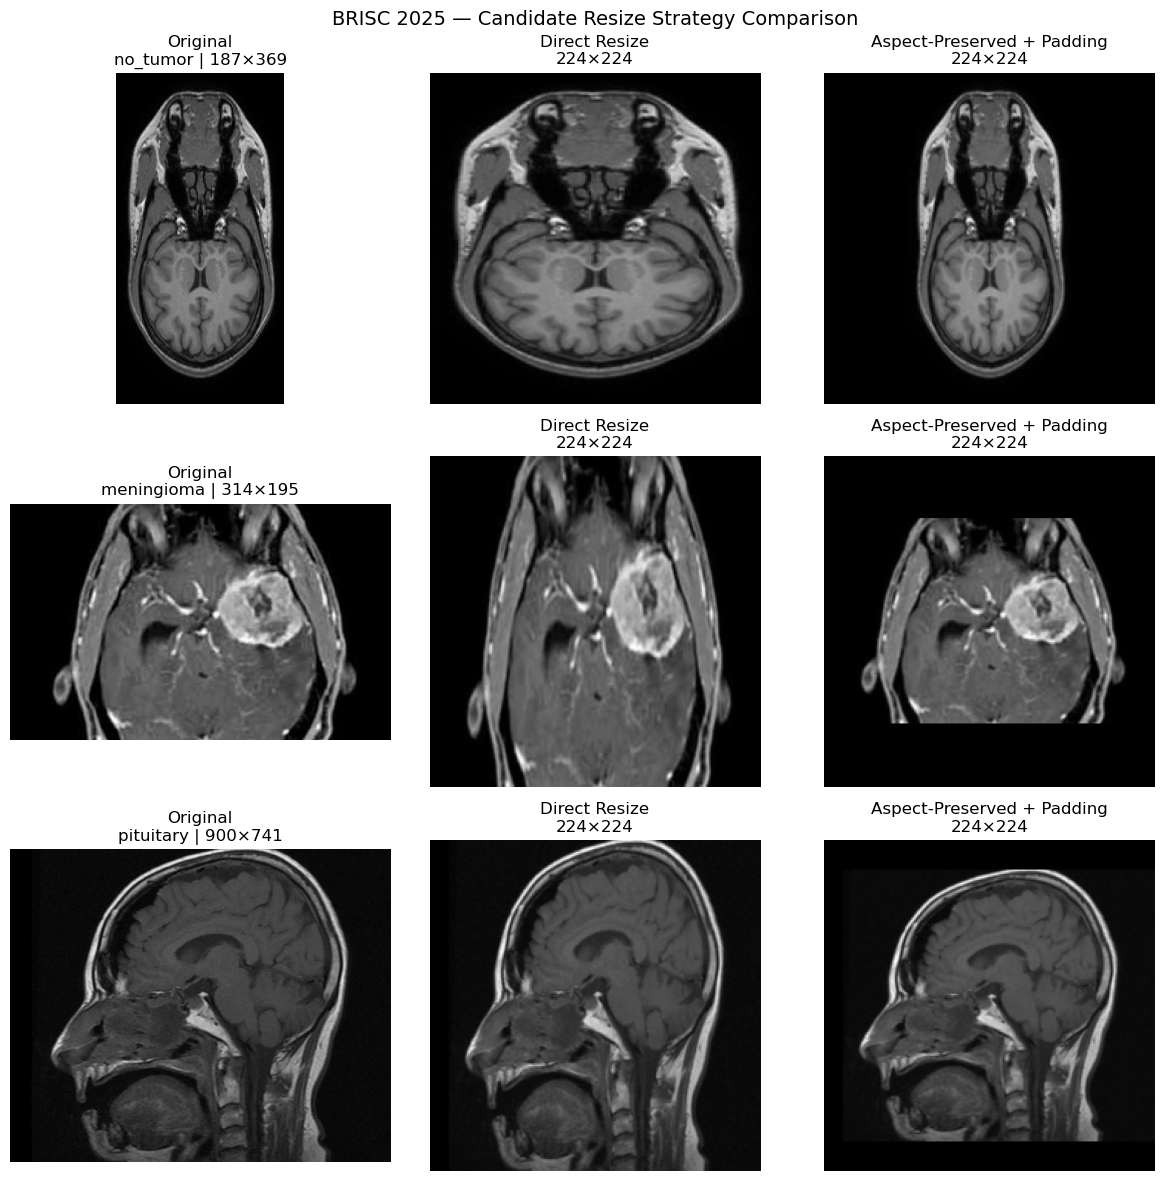

Figure saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\figures\preprocessing_resize_strategy_comparison.png


In [7]:
from PIL import ImageOps

# ------------------------------------------------------------
# Candidate resize functions
# ------------------------------------------------------------

AUDIT_SIZE = 224


def direct_square_resize(img, size=AUDIT_SIZE):
    """
    Directly resize image to a fixed square.
    """
    return img.resize(
        (size, size),
        resample=Image.Resampling.BILINEAR
    )


def aspect_preserving_pad(img, size=AUDIT_SIZE):
    """
    Preserve aspect ratio, then pad symmetrically to square.
    Used only for comparison at this stage.
    """

    img_copy = img.copy()

    img_copy.thumbnail(
        (size, size),
        resample=Image.Resampling.BILINEAR
    )

    canvas = Image.new(
        "L",
        (size, size),
        color=0
    )

    left = (size - img_copy.width) // 2
    top = (size - img_copy.height) // 2

    canvas.paste(
        img_copy,
        (left, top)
    )

    return canvas


# ------------------------------------------------------------
# Select representative non-square examples
# ------------------------------------------------------------

non_square_df = classification_geometry_df[
    ~classification_geometry_df["is_square"]
].copy()

# Pick representative classes where non-square images occur
audit_samples = []

for class_name in [
    "no_tumor",
    "meningioma",
    "pituitary"
]:

    class_candidates = non_square_df[
        non_square_df["tumor_label"] == class_name
    ]

    if len(class_candidates) > 0:

        # Prefer one of the more strongly non-square examples
        class_candidates = class_candidates.copy()

        class_candidates["aspect_deviation"] = (
            class_candidates["aspect_ratio"] - 1
        ).abs()

        selected = (
            class_candidates
            .sort_values(
                "aspect_deviation",
                ascending=False
            )
            .iloc[0]
        )

        audit_samples.append(selected)


# ------------------------------------------------------------
# Display original vs candidate strategies
# ------------------------------------------------------------

fig, axes = plt.subplots(
    len(audit_samples),
    3,
    figsize=(12, 4 * len(audit_samples))
)

if len(audit_samples) == 1:
    axes = np.array([axes])


for row_index, sample in enumerate(audit_samples):

    source_row = master_split_df[
        master_split_df["filename"]
        == sample["filename"]
    ].iloc[0]

    image_path = (
        DATASET_ROOT /
        Path(source_row["relative_path"])
    )

    with Image.open(image_path) as img:
        gray = img.convert("L")

        direct = direct_square_resize(gray)
        padded = aspect_preserving_pad(gray)

        axes[row_index, 0].imshow(
            gray,
            cmap="gray"
        )

        axes[row_index, 0].set_title(
            f"Original\n"
            f"{sample['tumor_label']} | "
            f"{gray.width}×{gray.height}"
        )

        axes[row_index, 1].imshow(
            direct,
            cmap="gray"
        )

        axes[row_index, 1].set_title(
            f"Direct Resize\n"
            f"{AUDIT_SIZE}×{AUDIT_SIZE}"
        )

        axes[row_index, 2].imshow(
            padded,
            cmap="gray"
        )

        axes[row_index, 2].set_title(
            f"Aspect-Preserved + Padding\n"
            f"{AUDIT_SIZE}×{AUDIT_SIZE}"
        )

        for column in range(3):
            axes[row_index, column].axis("off")


plt.suptitle(
    "BRISC 2025 — Candidate Resize Strategy Comparison",
    fontsize=14
)

plt.tight_layout()

resize_audit_path = (
    FIGURES_ROOT /
    "preprocessing_resize_strategy_comparison.png"
)

plt.savefig(
    resize_audit_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:")
print(resize_audit_path)

## 2.4 Foreground-Aware Image Framing Audit

The initial resize comparison showed that direct square resizing can visibly
distort strongly non-square MRI images, while aspect-ratio-preserving padding
introduces conspicuous borders that may expose class-correlated source geometry.

Before selecting either strategy, external dark image margins are examined.

A conservative foreground bounding box is estimated from grayscale intensity
values. Only external near-black canvas regions are trimmed; no final cropping
policy is adopted until the resulting geometry and representative images are
visually verified.

In [9]:
# ------------------------------------------------------------
# Conservative dark-background trimming
# ------------------------------------------------------------

BACKGROUND_THRESHOLD = 10
CROP_MARGIN_FRACTION = 0.03


def trim_dark_background(
    img,
    threshold=BACKGROUND_THRESHOLD,
    margin_fraction=CROP_MARGIN_FRACTION
):
    """
    Conservatively trim external near-black canvas.

    The function:
    - converts the image to grayscale;
    - finds pixels above a low background threshold;
    - constructs their bounding box;
    - adds a small safety margin;
    - returns the cropped grayscale image.

    This is currently an audit operation, not yet the
    final preprocessing policy.
    """

    gray = img.convert("L")
    arr = np.asarray(gray)

    foreground = arr > threshold

    if not foreground.any():
        return gray.copy()

    rows, cols = np.where(foreground)

    top = int(rows.min())
    bottom = int(rows.max()) + 1

    left = int(cols.min())
    right = int(cols.max()) + 1

    box_width = right - left
    box_height = bottom - top

    margin_x = int(
        round(box_width * margin_fraction)
    )

    margin_y = int(
        round(box_height * margin_fraction)
    )

    left = max(0, left - margin_x)
    right = min(gray.width, right + margin_x)

    top = max(0, top - margin_y)
    bottom = min(gray.height, bottom + margin_y)

    return gray.crop(
        (left, top, right, bottom)
    )

In [10]:
trimmed_geometry_records = []

print("Auditing foreground-aware image geometry...")
print("Images to inspect:", len(master_split_df))

for i, row in master_split_df.iterrows():

    image_path = (
        DATASET_ROOT /
        Path(row["relative_path"])
    )

    with Image.open(image_path) as img:

        gray = img.convert("L")
        trimmed = trim_dark_background(gray)

        original_width, original_height = gray.size
        trimmed_width, trimmed_height = trimmed.size

    trimmed_geometry_records.append({
        "filename": row["filename"],
        "model_split": row["model_split"],
        "tumor_label": row["tumor_label"],
        "plane_label": row["plane_label"],

        "original_width": original_width,
        "original_height": original_height,

        "trimmed_width": trimmed_width,
        "trimmed_height": trimmed_height,

        "original_aspect_ratio":
            original_width / original_height,

        "trimmed_aspect_ratio":
            trimmed_width / trimmed_height,

        "width_removed_percent":
            100 * (
                original_width - trimmed_width
            ) / original_width,

        "height_removed_percent":
            100 * (
                original_height - trimmed_height
            ) / original_height
    })

    if (i + 1) % 500 == 0:
        print(
            f"Processed {i + 1}/{len(master_split_df)}"
        )


trimmed_geometry_df = pd.DataFrame(
    trimmed_geometry_records
)

print("\nForeground framing audit complete.")
print(
    "Images inspected:",
    len(trimmed_geometry_df)
)

Auditing foreground-aware image geometry...
Images to inspect: 5862
Processed 500/5862
Processed 1000/5862
Processed 1500/5862
Processed 2000/5862
Processed 2500/5862
Processed 3000/5862
Processed 3500/5862
Processed 4000/5862
Processed 4500/5862
Processed 5000/5862
Processed 5500/5862

Foreground framing audit complete.
Images inspected: 5862


In [11]:
print("FOREGROUND-AWARE GEOMETRY SUMMARY")
print("-" * 70)

print("\nORIGINAL ASPECT RATIOS")

display(
    trimmed_geometry_df[
        "original_aspect_ratio"
    ]
    .describe()
    .round(4)
    .to_frame()
)

print("\nAFTER DARK-BACKGROUND TRIMMING")

display(
    trimmed_geometry_df[
        "trimmed_aspect_ratio"
    ]
    .describe()
    .round(4)
    .to_frame()
)


print("\nTRIMMED ASPECT RATIO BY CLASS")
print("-" * 70)

display(
    trimmed_geometry_df
    .groupby("tumor_label")[
        "trimmed_aspect_ratio"
    ]
    .agg(
        [
            "count",
            "mean",
            "median",
            "min",
            "max"
        ]
    )
    .round(4)
)


print("\nAMOUNT OF CANVAS REMOVED")
print("-" * 70)

display(
    trimmed_geometry_df[
        [
            "width_removed_percent",
            "height_removed_percent"
        ]
    ]
    .describe()
    .round(2)
)

FOREGROUND-AWARE GEOMETRY SUMMARY
----------------------------------------------------------------------

ORIGINAL ASPECT RATIOS


,original_aspect_ratio
count,5862.0000
mean,0.9697
std,0.1104
min,0.5068
25%,1.0000
50%,1.0000
75%,1.0000
max,1.6103



AFTER DARK-BACKGROUND TRIMMING


,trimmed_aspect_ratio
count,5862.0000
mean,0.9579
std,0.1361
min,0.4557
25%,0.9004
50%,1.0000
75%,1.0262
max,1.6765



TRIMMED ASPECT RATIO BY CLASS
----------------------------------------------------------------------


,count,mean,median,min,max
tumor_label,,,,,
glioma,1401,0.9534,0.9300,0.6787,1.6765
meningioma,1523,1.0066,1.0059,0.6844,1.5827
no_tumor,1198,0.8529,0.9274,0.4557,1.4000
pituitary,1740,0.9912,1.0000,0.7883,1.1795



AMOUNT OF CANVAS REMOVED
----------------------------------------------------------------------


,width_removed_percent,height_removed_percent
count,5862.00,5862.00
mean,9.30,8.15
std,10.55,8.20
min,0.00,0.00
25%,0.00,0.59
50%,4.27,6.23
75%,17.77,12.70
max,47.46,53.52


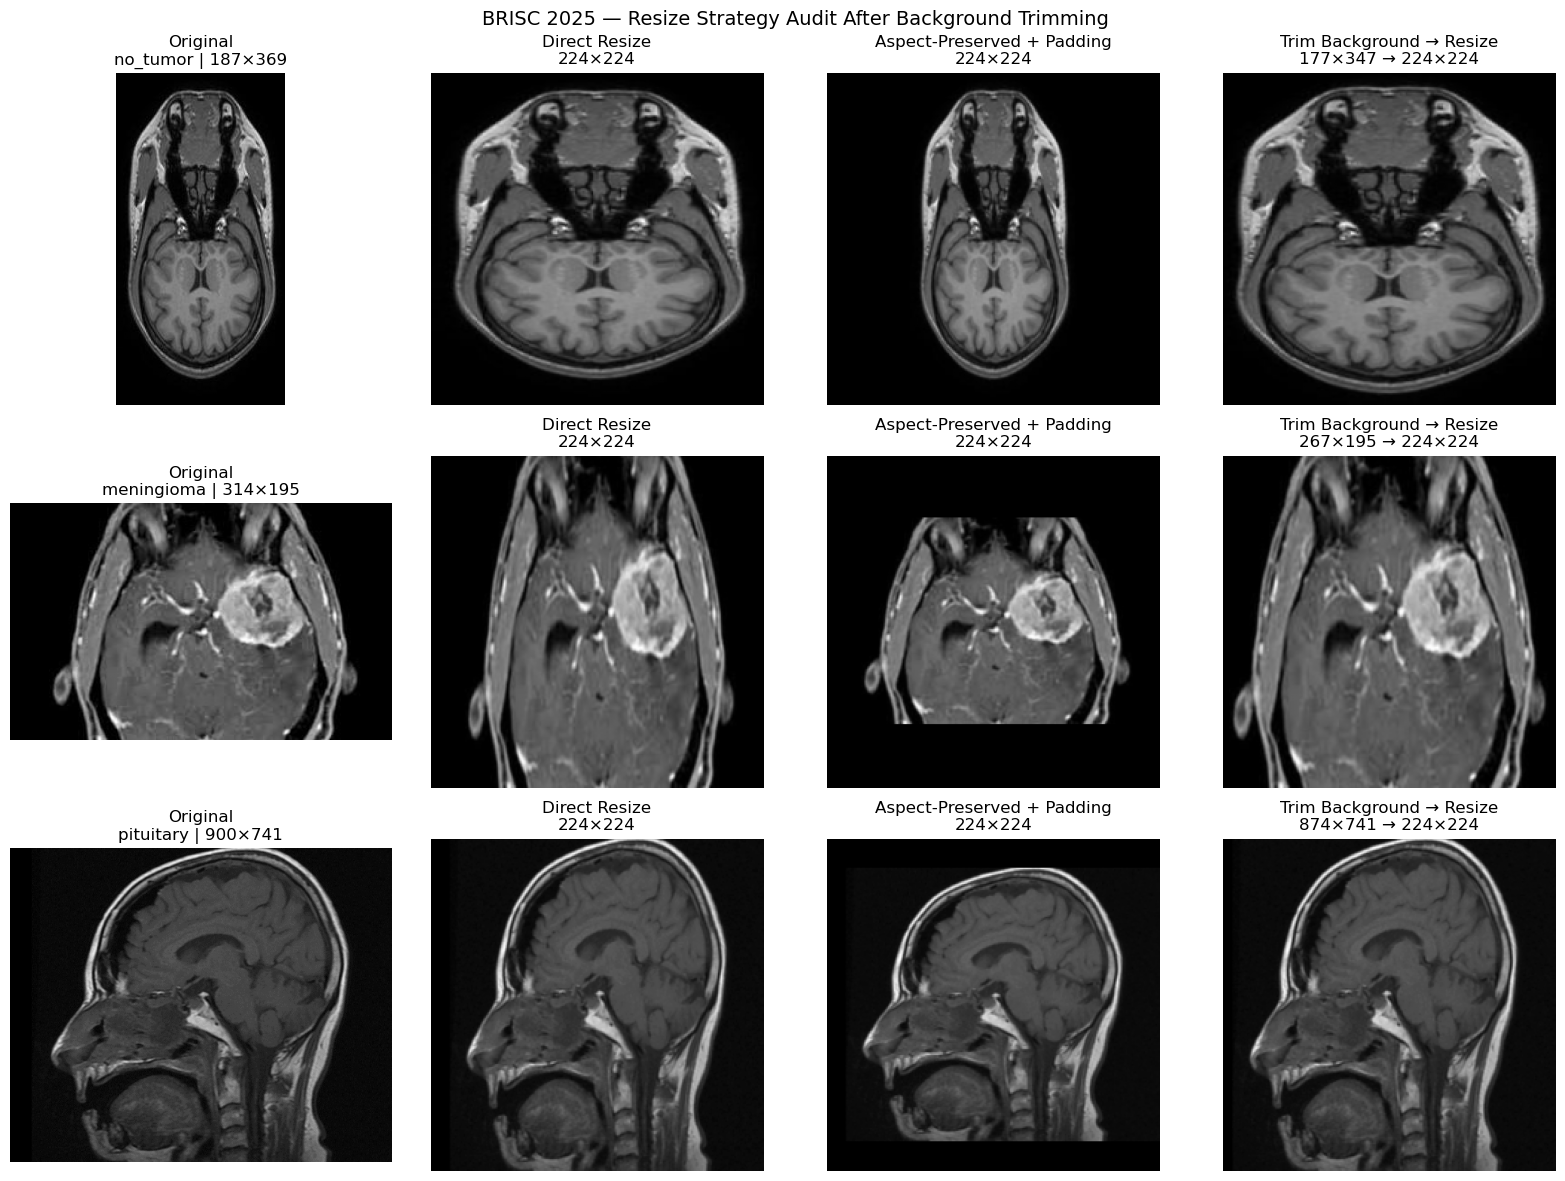

Figure saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\figures\preprocessing_background_trim_resize_comparison.png


In [12]:
fig, axes = plt.subplots(
    len(audit_samples),
    4,
    figsize=(16, 4 * len(audit_samples))
)

if len(audit_samples) == 1:
    axes = np.array([axes])


for row_index, sample in enumerate(audit_samples):

    source_row = master_split_df[
        master_split_df["filename"]
        == sample["filename"]
    ].iloc[0]

    image_path = (
        DATASET_ROOT /
        Path(source_row["relative_path"])
    )

    with Image.open(image_path) as img:

        gray = img.convert("L")

        direct = direct_square_resize(
            gray
        )

        padded = aspect_preserving_pad(
            gray
        )

        trimmed = trim_dark_background(
            gray
        )

        trimmed_square = direct_square_resize(
            trimmed
        )


    images = [
        gray,
        direct,
        padded,
        trimmed_square
    ]

    titles = [
        (
            f"Original\n"
            f"{sample['tumor_label']} | "
            f"{gray.width}×{gray.height}"
        ),
        "Direct Resize\n224×224",
        "Aspect-Preserved + Padding\n224×224",
        (
            "Trim Background → Resize\n"
            f"{trimmed.width}×{trimmed.height} → 224×224"
        )
    ]

    for col in range(4):

        axes[row_index, col].imshow(
            images[col],
            cmap="gray"
        )

        axes[row_index, col].set_title(
            titles[col]
        )

        axes[row_index, col].axis("off")


plt.suptitle(
    "BRISC 2025 — Resize Strategy Audit After Background Trimming",
    fontsize=14
)

plt.tight_layout()

trim_resize_figure_path = (
    FIGURES_ROOT /
    "preprocessing_background_trim_resize_comparison.png"
)

plt.savefig(
    trim_resize_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:")
print(trim_resize_figure_path)

## 2.5 Final Classification Spatial Standardization Decision

Three candidate spatial preprocessing strategies were evaluated:

1. direct square resizing;
2. aspect-ratio-preserving resizing with padding;
3. conservative dark-background trimming followed by square resizing.

Aspect-ratio-preserving padding maintained native image geometry but introduced
large and readily visible borders for strongly non-square images. Because native
geometry is substantially associated with tumor class, particularly the
no-tumor class, such borders could become a source-related shortcut feature.

Foreground-aware dark-background trimming did not resolve this issue. After
trimming, aspect-ratio variability increased rather than decreased, and some
images required substantial removal of external canvas. Visual inspection also
showed that trimming followed by square resizing did not eliminate geometric
distortion in strongly non-square cases.

Therefore, the primary classification pipeline will use direct resizing to a
fixed square input resolution.

This choice intentionally standardizes source-dependent framing and suppresses
native aspect-ratio cues across the dataset. Some geometric distortion is
accepted as a preprocessing limitation and will be documented accordingly.

The square target resolution remains configurable until the final model
architectures are selected.

All MRI images will first be canonicalized to grayscale. If a downstream model
requires three input channels, the grayscale image will be replicated across
three identical channels.

In [13]:
# ------------------------------------------------------------
# Canonical classification preprocessing configuration
# ------------------------------------------------------------

DEFAULT_INPUT_SIZE = 224

CLASSIFICATION_PREPROCESSING_CONFIG = {
    "canonical_mode": "L",
    "spatial_method": "direct_square_resize",
    "default_input_size": DEFAULT_INPUT_SIZE,
    "resize_interpolation": "bilinear",
    "background_trimming": False,
    "aspect_ratio_padding": False,
    "output_value_range": "0_to_1",
    "three_channel_policy": "replicate_grayscale_if_required"
}

print("CLASSIFICATION PREPROCESSING CONFIGURATION")
print("-" * 70)

for key, value in CLASSIFICATION_PREPROCESSING_CONFIG.items():
    print(f"{key}: {value}")

CLASSIFICATION PREPROCESSING CONFIGURATION
----------------------------------------------------------------------
canonical_mode: L
spatial_method: direct_square_resize
default_input_size: 224
resize_interpolation: bilinear
background_trimming: False
aspect_ratio_padding: False
output_value_range: 0_to_1
three_channel_policy: replicate_grayscale_if_required


In [14]:
def preprocess_classification_image(
    image_path,
    target_size=DEFAULT_INPUT_SIZE,
    output_channels=1
):
    """
    Deterministic BRISC classification preprocessing.

    Steps:
    1. Load image.
    2. Convert to canonical grayscale.
    3. Directly resize to target_size × target_size.
    4. Scale intensities to [0, 1].
    5. Optionally replicate grayscale into 3 channels.

    Parameters
    ----------
    image_path : str or Path
        Path to source MRI image.

    target_size : int
        Final square image size.

    output_channels : int
        Either 1 or 3.

    Returns
    -------
    numpy.ndarray
        Float32 image in [0, 1].
        Shape:
            (H, W) for 1 channel
            (H, W, 3) for 3 channels
    """

    if output_channels not in (1, 3):
        raise ValueError(
            "output_channels must be either 1 or 3."
        )

    with Image.open(image_path) as img:

        gray = img.convert("L")

        resized = gray.resize(
            (target_size, target_size),
            resample=Image.Resampling.BILINEAR
        )

        arr = np.asarray(
            resized,
            dtype=np.float32
        ) / 255.0

    if output_channels == 3:
        arr = np.repeat(
            arr[..., np.newaxis],
            3,
            axis=2
        )

    return arr

In [15]:
# ------------------------------------------------------------
# Test canonical preprocessing on representative records
# ------------------------------------------------------------

preprocess_test_records = pd.concat(
    [
        train_df.sample(
            n=3,
            random_state=42
        ),
        validation_df.sample(
            n=2,
            random_state=42
        ),
        test_df.sample(
            n=2,
            random_state=42
        )
    ],
    ignore_index=True
)

preprocess_check_records = []

for _, row in preprocess_test_records.iterrows():

    image_path = (
        DATASET_ROOT /
        Path(row["relative_path"])
    )

    gray_output = preprocess_classification_image(
        image_path,
        target_size=DEFAULT_INPUT_SIZE,
        output_channels=1
    )

    rgb_output = preprocess_classification_image(
        image_path,
        target_size=DEFAULT_INPUT_SIZE,
        output_channels=3
    )

    rgb_channels_identical = bool(
        np.array_equal(
            rgb_output[..., 0],
            rgb_output[..., 1]
        )
        and
        np.array_equal(
            rgb_output[..., 1],
            rgb_output[..., 2]
        )
    )

    preprocess_check_records.append({
        "filename": row["filename"],
        "model_split": row["model_split"],
        "gray_shape": str(gray_output.shape),
        "rgb_shape": str(rgb_output.shape),
        "gray_min": float(gray_output.min()),
        "gray_max": float(gray_output.max()),
        "dtype": str(gray_output.dtype),
        "rgb_channels_identical":
            rgb_channels_identical
    })


preprocess_check_df = pd.DataFrame(
    preprocess_check_records
)

print("CLASSIFICATION PREPROCESSING SANITY CHECK")
print("-" * 70)

display(preprocess_check_df)

print("\nSUMMARY")
print("-" * 70)

print(
    "All grayscale shapes correct:",
    all(
        shape == "(224, 224)"
        for shape in preprocess_check_df[
            "gray_shape"
        ]
    )
)

print(
    "All RGB shapes correct:",
    all(
        shape == "(224, 224, 3)"
        for shape in preprocess_check_df[
            "rgb_shape"
        ]
    )
)

print(
    "All replicated RGB channels identical:",
    preprocess_check_df[
        "rgb_channels_identical"
    ].all()
)

print(
    "All values within [0, 1]:",
    bool(
        (
            preprocess_check_df["gray_min"] >= 0
        ).all()
        and
        (
            preprocess_check_df["gray_max"] <= 1
        ).all()
    )
)

CLASSIFICATION PREPROCESSING SANITY CHECK
----------------------------------------------------------------------


,filename,model_split,gray_shape,rgb_shape,gray_min,gray_max,dtype,rgb_channels_identical
0,brisc2025_train_04376_pi_co_t1.jpg,train,"(224, 224)","(224, 224, 3)",0.0,0.937255,float32,True
1,brisc2025_train_03808_pi_ax_t1.jpg,train,"(224, 224)","(224, 224, 3)",0.0,0.976471,float32,True
2,brisc2025_train_03069_no_co_t1.jpg,train,"(224, 224)","(224, 224, 3)",0.0,0.917647,float32,True
3,brisc2025_train_00948_gl_sa_t1.jpg,validation,"(224, 224)","(224, 224, 3)",0.0,0.847059,float32,True
4,brisc2025_train_03520_no_sa_t1.jpg,validation,"(224, 224)","(224, 224, 3)",0.0,1.000000,float32,True
5,brisc2025_test_00522_me_sa_t1.jpg,test,"(224, 224)","(224, 224, 3)",0.0,0.964706,float32,True
6,brisc2025_test_00738_pi_ax_t1.jpg,test,"(224, 224)","(224, 224, 3)",0.0,0.870588,float32,True



SUMMARY
----------------------------------------------------------------------
All grayscale shapes correct: True
All RGB shapes correct: True
All replicated RGB channels identical: True
All values within [0, 1]: True


## 3. Segmentation MRI–Mask Preprocessing

The BRISC segmentation task contains 4,793 MRI–mask pairs.

Previous integrity and EDA analysis established that:

- every segmentation MRI has a corresponding mask;
- MRI and mask dimensions match within each pair;
- segmentation masks use near-black background values (0–10) and near-white
  foreground values (246–255);
- no pixels occur in the intermediate range 11–245;
- a threshold of 128 therefore safely converts the masks to binary form.

For spatial preprocessing, the MRI and its corresponding mask must undergo the
same geometric transformation so that pixel-wise alignment is preserved.

MRI images are resized using bilinear interpolation, while binary segmentation
masks are resized using nearest-neighbor interpolation to prevent the creation
of artificial intermediate label values.

In [16]:
# ------------------------------------------------------------
# Build segmentation MRI-mask pair table
# ------------------------------------------------------------

segmentation_mri_lookup = (
    segmentation_mri_df[
        [
            "relative_path",
            "filename",
            "split",
            "tumor_label",
            "plane_label"
        ]
    ]
    .copy()
)

segmentation_mri_lookup = segmentation_mri_lookup.rename(
    columns={
        "relative_path": "mri_relative_path",
        "filename": "mri_filename",
        "split": "mri_split",
        "tumor_label": "mri_tumor_label",
        "plane_label": "mri_plane_label"
    }
)


segmentation_pairs_df = (
    segmentation_mask_df[
        [
            "relative_path",
            "filename",
            "linked_image",
            "split",
            "tumor_label",
            "plane_label"
        ]
    ]
    .copy()
)

segmentation_pairs_df = segmentation_pairs_df.rename(
    columns={
        "relative_path": "mask_relative_path",
        "filename": "mask_filename"
    }
)

# linked_image contains the MRI relative path
segmentation_pairs_df = segmentation_pairs_df.merge(
    segmentation_mri_lookup,
    left_on="linked_image",
    right_on="mri_relative_path",
    how="left"
)


print("SEGMENTATION PAIR TABLE")
print("-" * 70)

print(
    "Mask records:",
    len(segmentation_pairs_df)
)

print(
    "MRI links resolved:",
    segmentation_pairs_df[
        "mri_relative_path"
    ].notna().sum()
)

print(
    "MRI links missing:",
    segmentation_pairs_df[
        "mri_relative_path"
    ].isna().sum()
)


print("\nPAIR METADATA CONSISTENCY")
print("-" * 70)

print(
    "Split mismatches:",
    (
        segmentation_pairs_df["split"]
        != segmentation_pairs_df["mri_split"]
    ).sum()
)

print(
    "Tumor-label mismatches:",
    (
        segmentation_pairs_df["tumor_label"]
        != segmentation_pairs_df["mri_tumor_label"]
    ).sum()
)

print(
    "Plane-label mismatches:",
    (
        segmentation_pairs_df["plane_label"]
        != segmentation_pairs_df["mri_plane_label"]
    ).sum()
)


# Hard verification
assert len(segmentation_pairs_df) == 4793

assert (
    segmentation_pairs_df[
        "mri_relative_path"
    ].isna().sum()
    == 0
)

assert (
    segmentation_pairs_df["split"]
    != segmentation_pairs_df["mri_split"]
).sum() == 0

assert (
    segmentation_pairs_df["tumor_label"]
    != segmentation_pairs_df["mri_tumor_label"]
).sum() == 0

assert (
    segmentation_pairs_df["plane_label"]
    != segmentation_pairs_df["mri_plane_label"]
).sum() == 0

print("\nAll segmentation pair checks PASSED.")

SEGMENTATION PAIR TABLE
----------------------------------------------------------------------
Mask records: 4793
MRI links resolved: 4793
MRI links missing: 0

PAIR METADATA CONSISTENCY
----------------------------------------------------------------------
Split mismatches: 0
Tumor-label mismatches: 0
Plane-label mismatches: 0

All segmentation pair checks PASSED.


### 3.1 Deterministic MRI–Mask Transformation

Each MRI–mask pair is transformed jointly using the same target dimensions.

The MRI is converted to grayscale, resized using bilinear interpolation, and
scaled to the range [0, 1].

The original grayscale mask is first converted to a binary mask using the
validated threshold of 128. The binary mask is then resized using
nearest-neighbor interpolation so that its categorical foreground/background
structure is preserved.

In [17]:
# ------------------------------------------------------------
# Segmentation preprocessing configuration
# ------------------------------------------------------------

SEGMENTATION_INPUT_SIZE = 224
MASK_THRESHOLD = 128

SEGMENTATION_PREPROCESSING_CONFIG = {
    "mri_canonical_mode": "L",
    "target_size": SEGMENTATION_INPUT_SIZE,
    "mri_resize_interpolation": "bilinear",
    "mask_threshold": MASK_THRESHOLD,
    "mask_resize_interpolation": "nearest",
    "mri_output_range": "0_to_1",
    "mask_output_values": [0, 1]
}

print("SEGMENTATION PREPROCESSING CONFIGURATION")
print("-" * 70)

for key, value in SEGMENTATION_PREPROCESSING_CONFIG.items():
    print(f"{key}: {value}")

SEGMENTATION PREPROCESSING CONFIGURATION
----------------------------------------------------------------------
mri_canonical_mode: L
target_size: 224
mri_resize_interpolation: bilinear
mask_threshold: 128
mask_resize_interpolation: nearest
mri_output_range: 0_to_1
mask_output_values: [0, 1]


In [18]:
def preprocess_segmentation_pair(
    mri_path,
    mask_path,
    target_size=SEGMENTATION_INPUT_SIZE,
    mri_output_channels=1
):
    """
    Deterministically preprocess one BRISC MRI-mask pair.

    MRI:
        grayscale
        -> bilinear square resize
        -> float32 [0, 1]

    Mask:
        grayscale
        -> threshold >= 128
        -> nearest-neighbor square resize
        -> uint8 {0, 1}
    """

    if mri_output_channels not in (1, 3):
        raise ValueError(
            "mri_output_channels must be either 1 or 3."
        )

    # ---------------- MRI ----------------

    with Image.open(mri_path) as img:

        gray_mri = img.convert("L")

        resized_mri = gray_mri.resize(
            (target_size, target_size),
            resample=Image.Resampling.BILINEAR
        )

        mri_arr = np.asarray(
            resized_mri,
            dtype=np.float32
        ) / 255.0

    if mri_output_channels == 3:

        mri_arr = np.repeat(
            mri_arr[..., np.newaxis],
            3,
            axis=2
        )

    # ---------------- Mask ----------------

    with Image.open(mask_path) as mask:

        mask_gray = np.asarray(
            mask.convert("L")
        )

    binary_mask = (
        mask_gray >= MASK_THRESHOLD
    ).astype(np.uint8)

    binary_mask_pil = Image.fromarray(
        binary_mask * 255,
        mode="L"
    )

    resized_mask = binary_mask_pil.resize(
        (target_size, target_size),
        resample=Image.Resampling.NEAREST
    )

    mask_arr = (
        np.asarray(resized_mask) >= 128
    ).astype(np.uint8)

    return mri_arr, mask_arr

In [19]:
# ------------------------------------------------------------
# Segmentation preprocessing sanity check
# ------------------------------------------------------------

segmentation_sample_df = (
    segmentation_pairs_df
    .sample(
        n=8,
        random_state=42
    )
    .reset_index(drop=True)
)

segmentation_check_records = []

for _, row in segmentation_sample_df.iterrows():

    mri_path = (
        DATASET_ROOT /
        Path(row["mri_relative_path"])
    )

    mask_path = (
        DATASET_ROOT /
        Path(row["mask_relative_path"])
    )

    mri_arr, mask_arr = preprocess_segmentation_pair(
        mri_path,
        mask_path,
        target_size=SEGMENTATION_INPUT_SIZE,
        mri_output_channels=1
    )

    unique_mask_values = np.unique(
        mask_arr
    )

    segmentation_check_records.append({
        "mri_filename": row["mri_filename"],
        "mask_filename": row["mask_filename"],
        "split": row["split"],
        "tumor_label": row["tumor_label"],
        "mri_shape": str(mri_arr.shape),
        "mask_shape": str(mask_arr.shape),
        "mri_min": float(mri_arr.min()),
        "mri_max": float(mri_arr.max()),
        "mri_dtype": str(mri_arr.dtype),
        "mask_dtype": str(mask_arr.dtype),
        "mask_values": str(
            unique_mask_values.tolist()
        ),
        "foreground_pixels": int(
            mask_arr.sum()
        )
    })


segmentation_check_df = pd.DataFrame(
    segmentation_check_records
)

print("SEGMENTATION PREPROCESSING SANITY CHECK")
print("-" * 70)

display(segmentation_check_df)


print("\nSUMMARY")
print("-" * 70)

print(
    "All MRI shapes correct:",
    all(
        shape == "(224, 224)"
        for shape in segmentation_check_df[
            "mri_shape"
        ]
    )
)

print(
    "All mask shapes correct:",
    all(
        shape == "(224, 224)"
        for shape in segmentation_check_df[
            "mask_shape"
        ]
    )
)

print(
    "All MRI values within [0, 1]:",
    bool(
        (
            segmentation_check_df["mri_min"] >= 0
        ).all()
        and
        (
            segmentation_check_df["mri_max"] <= 1
        ).all()
    )
)

print(
    "All masks remain binary:",
    all(
        values in ("[0, 1]", "[1, 0]")
        for values in segmentation_check_df[
            "mask_values"
        ]
    )
)

print(
    "All masks contain foreground:",
    bool(
        (
            segmentation_check_df[
                "foreground_pixels"
            ] > 0
        ).all()
    )
)

SEGMENTATION PREPROCESSING SANITY CHECK
----------------------------------------------------------------------


,mri_filename,mask_filename,split,tumor_label,mri_shape,mask_shape,mri_min,mri_max,mri_dtype,mask_dtype,mask_values,foreground_pixels
0,brisc2025_test_00702_pi_ax_t1.jpg,brisc2025_test_00702_pi_ax_t1.png,test,pituitary,"(224, 224)","(224, 224)",0.0,0.858824,float32,uint8,"[0, 1]",323
1,brisc2025_train_00034_gl_ax_t1.jpg,brisc2025_train_00034_gl_ax_t1.png,train,glioma,"(224, 224)","(224, 224)",0.0,0.854902,float32,uint8,"[0, 1]",984
2,brisc2025_train_00825_gl_sa_t1.jpg,brisc2025_train_00825_gl_sa_t1.png,train,glioma,"(224, 224)","(224, 224)",0.0,0.909804,float32,uint8,"[0, 1]",476
3,brisc2025_test_00846_pi_co_t1.jpg,brisc2025_test_00846_pi_co_t1.png,test,pituitary,"(224, 224)","(224, 224)",0.0,0.843137,float32,uint8,"[0, 1]",410
4,brisc2025_train_01014_gl_sa_t1.jpg,brisc2025_train_01014_gl_sa_t1.png,train,glioma,"(224, 224)","(224, 224)",0.0,0.894118,float32,uint8,"[0, 1]",1091
5,brisc2025_train_01837_me_co_t1.jpg,brisc2025_train_01837_me_co_t1.png,train,meningioma,"(224, 224)","(224, 224)",0.0,0.925490,float32,uint8,"[0, 1]",1199
6,brisc2025_train_02158_me_sa_t1.jpg,brisc2025_train_02158_me_sa_t1.png,train,meningioma,"(224, 224)","(224, 224)",0.0,0.960784,float32,uint8,"[0, 1]",929
7,brisc2025_train_04687_pi_sa_t1.jpg,brisc2025_train_04687_pi_sa_t1.png,train,pituitary,"(224, 224)","(224, 224)",0.0,0.878431,float32,uint8,"[0, 1]",379



SUMMARY
----------------------------------------------------------------------
All MRI shapes correct: True
All mask shapes correct: True
All MRI values within [0, 1]: True
All masks remain binary: True
All masks contain foreground: True


### 3.2 Visual Verification of Preprocessed MRI–Mask Alignment

Representative MRI–mask pairs are visually inspected after deterministic
preprocessing.

The MRI and binary mask are displayed separately and as an overlay to verify
that resizing preserves their spatial correspondence and that no visible
mask displacement, orientation error, or threshold-related loss is introduced.

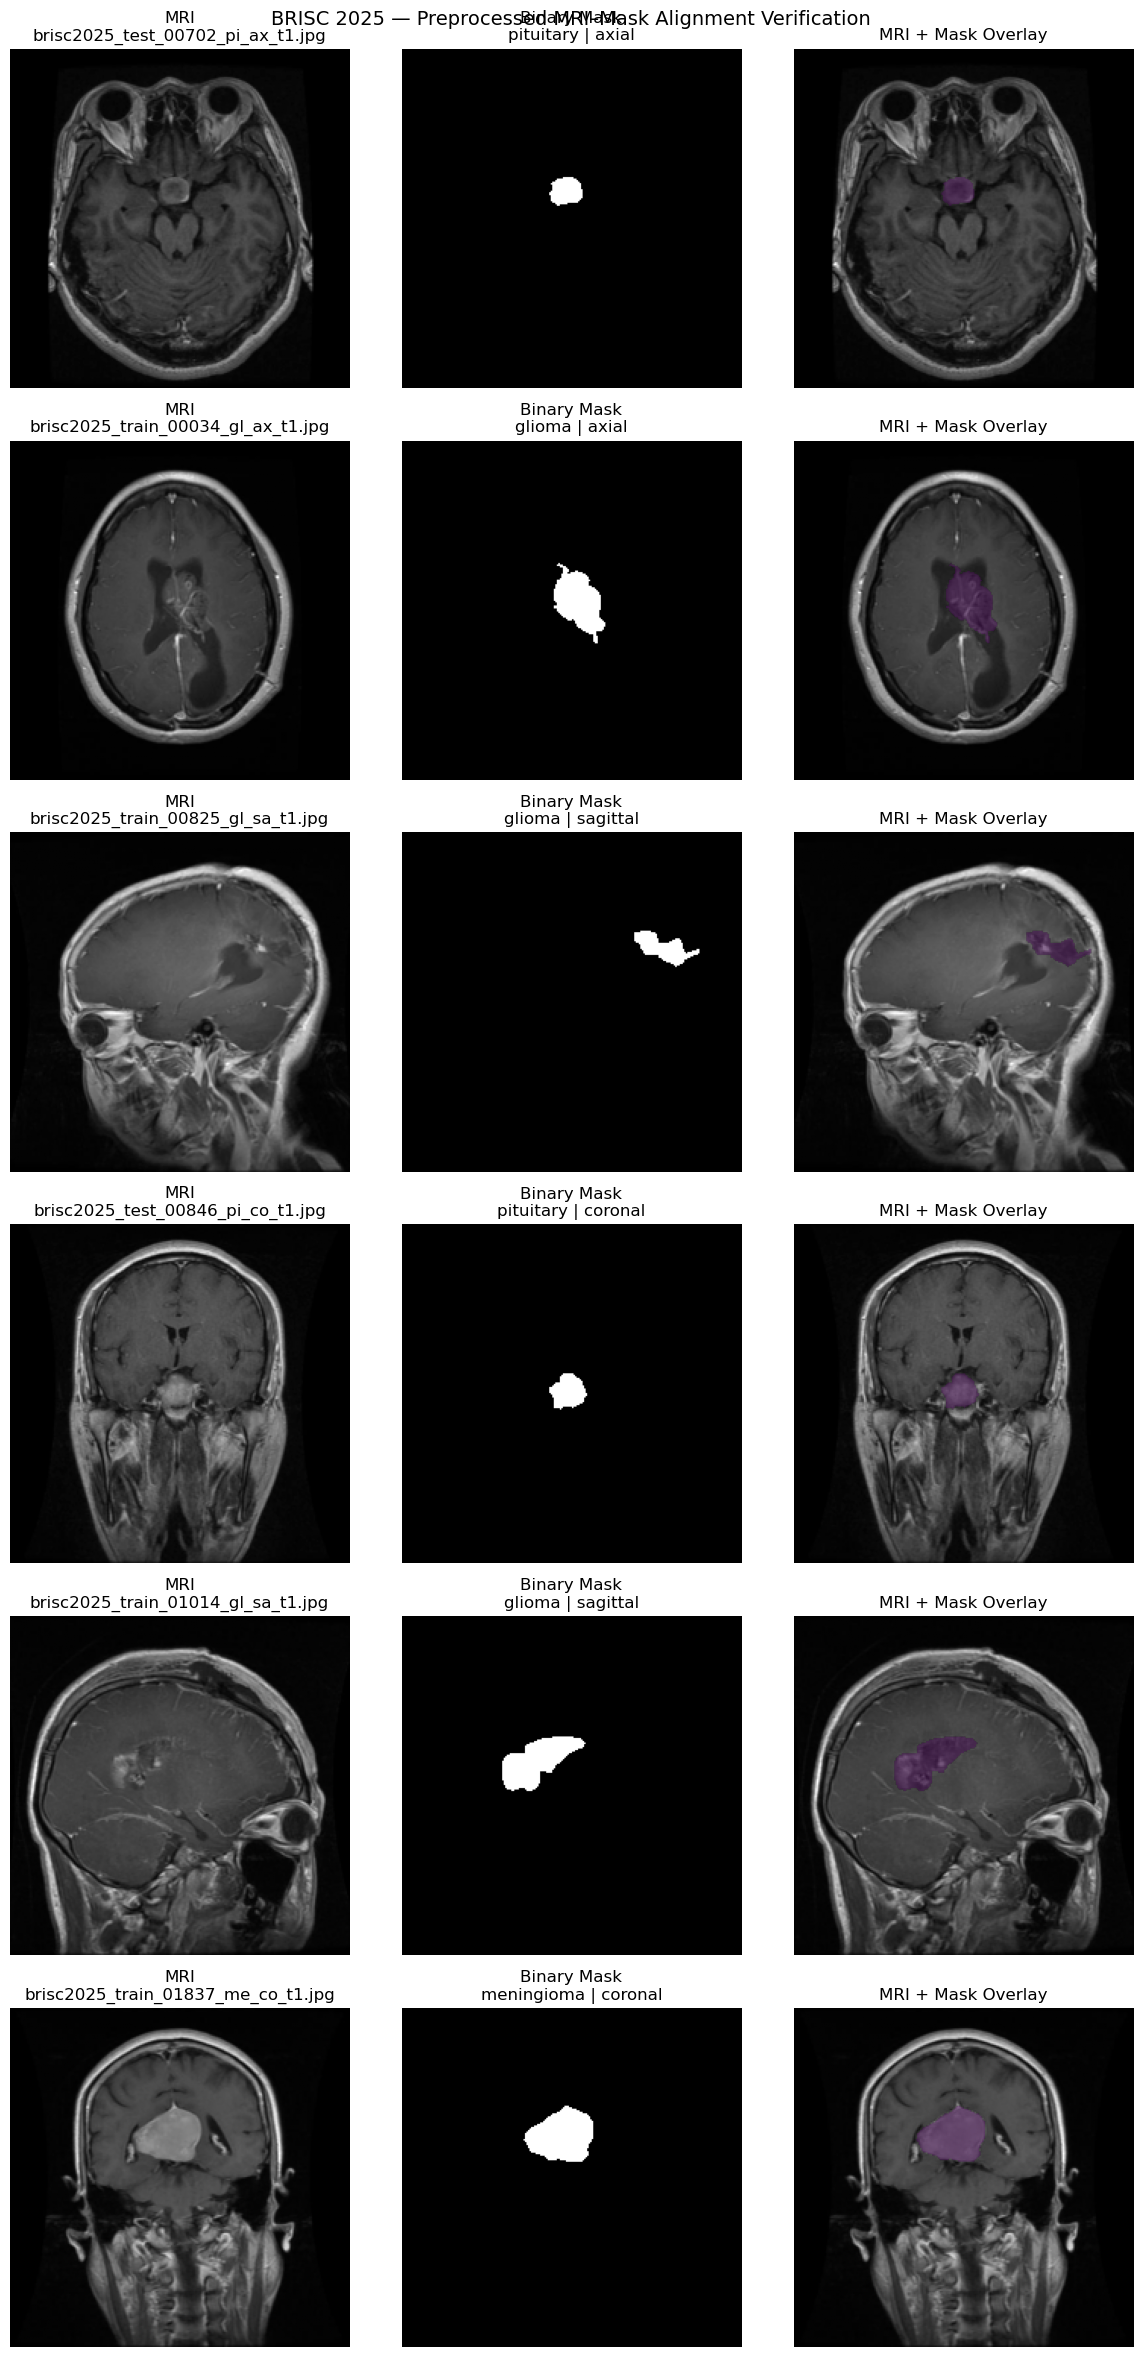

Figure saved to:
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\outputs\figures\preprocessing_segmentation_alignment_verification.png


In [20]:
# ------------------------------------------------------------
# Visual verification of resized MRI-mask alignment
# ------------------------------------------------------------

visual_segmentation_samples = (
    segmentation_pairs_df
    .sample(
        n=6,
        random_state=42
    )
    .reset_index(drop=True)
)

fig, axes = plt.subplots(
    len(visual_segmentation_samples),
    3,
    figsize=(12, 4 * len(visual_segmentation_samples))
)

for row_index, row in visual_segmentation_samples.iterrows():

    mri_path = (
        DATASET_ROOT /
        Path(row["mri_relative_path"])
    )

    mask_path = (
        DATASET_ROOT /
        Path(row["mask_relative_path"])
    )

    mri_arr, mask_arr = preprocess_segmentation_pair(
        mri_path,
        mask_path,
        target_size=SEGMENTATION_INPUT_SIZE,
        mri_output_channels=1
    )

    # MRI
    axes[row_index, 0].imshow(
        mri_arr,
        cmap="gray"
    )
    axes[row_index, 0].set_title(
        f"MRI\n{row['mri_filename']}"
    )

    # Binary mask
    axes[row_index, 1].imshow(
        mask_arr,
        cmap="gray"
    )
    axes[row_index, 1].set_title(
        f"Binary Mask\n"
        f"{row['tumor_label']} | {row['plane_label']}"
    )

    # Overlay
    axes[row_index, 2].imshow(
        mri_arr,
        cmap="gray"
    )

    masked_overlay = np.ma.masked_where(
        mask_arr == 0,
        mask_arr
    )

    axes[row_index, 2].imshow(
        masked_overlay,
        alpha=0.45
    )

    axes[row_index, 2].set_title(
        "MRI + Mask Overlay"
    )

    for column in range(3):
        axes[row_index, column].axis("off")


plt.suptitle(
    "BRISC 2025 — Preprocessed MRI–Mask Alignment Verification",
    fontsize=14
)

plt.tight_layout()

alignment_figure_path = (
    FIGURES_ROOT /
    "preprocessing_segmentation_alignment_verification.png"
)

plt.savefig(
    alignment_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:")
print(alignment_figure_path)

### 3.3 Quantitative Tumor-Area Preservation After Resizing

To verify that deterministic resizing does not substantially alter the relative
tumor area, foreground coverage is compared before and after preprocessing for
all 4,793 segmentation masks.

Because images have different native resolutions, comparison is performed using
foreground percentage rather than raw foreground-pixel count.

Nearest-neighbor interpolation is expected to preserve binary mask structure,
although very small discretization differences may occur after resizing.

In [21]:
# ------------------------------------------------------------
# Quantitative tumor-area preservation audit
# ------------------------------------------------------------

area_preservation_records = []

print("Auditing tumor-area preservation...")
print("Masks to process:", len(segmentation_pairs_df))

for i, row in segmentation_pairs_df.iterrows():

    mask_path = (
        DATASET_ROOT /
        Path(row["mask_relative_path"])
    )

    # ---------------- Original binary mask ----------------

    with Image.open(mask_path) as mask:

        original_mask = np.asarray(
            mask.convert("L")
        )

    original_binary = (
        original_mask >= MASK_THRESHOLD
    ).astype(np.uint8)

    original_foreground_percent = (
        100
        * original_binary.sum()
        / original_binary.size
    )

    # ---------------- Resized binary mask ----------------

    original_binary_pil = Image.fromarray(
        original_binary * 255,
        mode="L"
    )

    resized_mask = original_binary_pil.resize(
        (
            SEGMENTATION_INPUT_SIZE,
            SEGMENTATION_INPUT_SIZE
        ),
        resample=Image.Resampling.NEAREST
    )

    resized_binary = (
        np.asarray(resized_mask) >= 128
    ).astype(np.uint8)

    resized_foreground_percent = (
        100
        * resized_binary.sum()
        / resized_binary.size
    )

    absolute_difference = abs(
        resized_foreground_percent
        - original_foreground_percent
    )

    relative_difference_percent = (
        100
        * absolute_difference
        / original_foreground_percent
        if original_foreground_percent > 0
        else np.nan
    )

    area_preservation_records.append({
        "mask_filename": row["mask_filename"],
        "split": row["split"],
        "tumor_label": row["tumor_label"],
        "plane_label": row["plane_label"],
        "original_foreground_percent":
            original_foreground_percent,
        "resized_foreground_percent":
            resized_foreground_percent,
        "absolute_difference_pct_points":
            absolute_difference,
        "relative_difference_percent":
            relative_difference_percent
    })

    if (i + 1) % 500 == 0:
        print(
            f"Processed {i + 1}/{len(segmentation_pairs_df)}"
        )


area_preservation_df = pd.DataFrame(
    area_preservation_records
)

print("\nTumor-area preservation audit complete.")

Auditing tumor-area preservation...
Masks to process: 4793
Processed 500/4793
Processed 1000/4793
Processed 1500/4793
Processed 2000/4793
Processed 2500/4793
Processed 3000/4793
Processed 3500/4793
Processed 4000/4793
Processed 4500/4793

Tumor-area preservation audit complete.


In [22]:
print("TUMOR-AREA PRESERVATION SUMMARY")
print("-" * 70)

display(
    area_preservation_df[
        [
            "original_foreground_percent",
            "resized_foreground_percent",
            "absolute_difference_pct_points",
            "relative_difference_percent"
        ]
    ]
    .describe()
    .round(4)
)


print("\nABSOLUTE DIFFERENCE THRESHOLDS")
print("-" * 70)

for threshold in [
    0.01,
    0.05,
    0.10,
    0.25,
    0.50
]:

    count = (
        area_preservation_df[
            "absolute_difference_pct_points"
        ] > threshold
    ).sum()

    print(
        f"> {threshold:.2f} percentage points:",
        count
    )


print("\nMEAN ABSOLUTE DIFFERENCE BY CLASS")
print("-" * 70)

display(
    area_preservation_df
    .groupby("tumor_label")[
        "absolute_difference_pct_points"
    ]
    .agg(
        [
            "count",
            "mean",
            "median",
            "max"
        ]
    )
    .round(4)
)


print("\nCORRELATION BETWEEN ORIGINAL AND RESIZED TUMOR AREA")
print("-" * 70)

area_correlation = (
    area_preservation_df[
        [
            "original_foreground_percent",
            "resized_foreground_percent"
        ]
    ]
    .corr()
    .iloc[0, 1]
)

print(
    "Pearson correlation:",
    round(area_correlation, 6)
)

TUMOR-AREA PRESERVATION SUMMARY
----------------------------------------------------------------------


,original_foreground_percent,resized_foreground_percent,absolute_difference_pct_points,relative_difference_percent
count,4793.0000,4793.0000,4793.0000,4793.0000
mean,1.6937,1.6951,0.0070,0.6229
std,1.4973,1.4982,0.0073,0.7123
min,0.0088,0.0080,0.0000,0.0000
25%,0.7099,0.7115,0.0024,0.1845
50%,1.2554,1.2556,0.0052,0.4076
75%,2.1439,2.1504,0.0092,0.7979
max,17.3472,17.3330,0.1096,9.2393



ABSOLUTE DIFFERENCE THRESHOLDS
----------------------------------------------------------------------
> 0.01 percentage points: 1042
> 0.05 percentage points: 20
> 0.10 percentage points: 2
> 0.25 percentage points: 0
> 0.50 percentage points: 0

MEAN ABSOLUTE DIFFERENCE BY CLASS
----------------------------------------------------------------------


,count,mean,median,max
tumor_label,,,,
glioma,1401,0.0067,0.0053,0.0393
meningioma,1635,0.0087,0.0061,0.1096
pituitary,1757,0.0055,0.0044,0.0350



CORRELATION BETWEEN ORIGINAL AND RESIZED TUMOR AREA
----------------------------------------------------------------------
Pearson correlation: 0.999978


### Tumor-Area Preservation — Interpretation

Nearest-neighbor resizing preserved segmentation-mask foreground coverage with
very high fidelity.

Across all 4,793 masks, the mean absolute difference between native-resolution
and resized tumor coverage was only 0.0070 percentage points. The correlation
between original and resized tumor-area percentages was 0.999978.

Only 20 masks differed by more than 0.05 percentage points, only two differed
by more than 0.10 percentage points, and none differed by more than 0.25
percentage points.

Although the maximum relative percentage difference was larger for some very
small tumor regions, the corresponding absolute differences remained small.
This occurs because minor pixel changes can produce a comparatively large
relative change when the original foreground region contains very few pixels.

Together with the visual MRI-mask overlay inspection, these results support the
use of bilinear MRI resizing and nearest-neighbor binary-mask resizing for
deterministic segmentation preprocessing.

## 4. Training-Only Data Augmentation Policy

Deterministic preprocessing and stochastic data augmentation are treated as
separate stages.

Deterministic preprocessing is applied consistently to training, validation,
and testing data. Random augmentation, in contrast, is permitted only for the
training subset.

Because MRI anatomy and tumor morphology must remain clinically plausible,
augmentation is intentionally conservative. Large rotations, aggressive
warping, arbitrary crops, and vertical flips are avoided.

The initial augmentation policy consists of:

- small rotations;
- mild translations;
- mild scaling/zoom;
- limited intensity variation.

Horizontal and vertical flips are not enabled by default. Anatomical orientation
and laterality may carry meaningful spatial information, and the BRISC dataset
also contains axial, coronal, and sagittal views.

The exact implementation will be attached to the training data loader after the
deep-learning framework and final model architectures are selected.

In [23]:
# ------------------------------------------------------------
# Model-independent augmentation policy
# ------------------------------------------------------------

AUGMENTATION_POLICY = {
    "apply_to_train_only": True,
    "apply_to_validation": False,
    "apply_to_test": False,

    "rotation_degrees": (-7, 7),

    "translation_fraction": {
        "horizontal": 0.05,
        "vertical": 0.05
    },

    "scale_range": (0.95, 1.05),

    "brightness_factor_range": (0.95, 1.05),
    "contrast_factor_range": (0.95, 1.05),

    "horizontal_flip": False,
    "vertical_flip": False,

    "elastic_deformation": False,
    "random_crop": False,

    "segmentation_spatial_sync_required": True,
    "segmentation_mask_interpolation": "nearest"
}

print("TRAINING-ONLY AUGMENTATION POLICY")
print("-" * 70)

for key, value in AUGMENTATION_POLICY.items():
    print(f"{key}: {value}")

TRAINING-ONLY AUGMENTATION POLICY
----------------------------------------------------------------------
apply_to_train_only: True
apply_to_validation: False
apply_to_test: False
rotation_degrees: (-7, 7)
translation_fraction: {'horizontal': 0.05, 'vertical': 0.05}
scale_range: (0.95, 1.05)
brightness_factor_range: (0.95, 1.05)
contrast_factor_range: (0.95, 1.05)
horizontal_flip: False
vertical_flip: False
elastic_deformation: False
random_crop: False
segmentation_spatial_sync_required: True
segmentation_mask_interpolation: nearest


## 5. Intensity Normalization Strategy

All deterministic preprocessing functions currently scale grayscale MRI
intensities from the native 8-bit range [0, 255] to [0, 1].

No additional architecture-specific normalization is permanently applied at
this stage.

This distinction is intentional:

- a custom CNN may operate directly on [0, 1] inputs;
- an ImageNet-pretrained architecture may require model-specific mean and
  standard-deviation normalization after grayscale replication to three
  channels;
- different pretrained architectures may define different recommended input
  transformations.

Therefore, [0, 1] scaling is treated as the canonical dataset-level
representation, while any model-specific normalization will be added later in
the model-training pipeline and documented separately.

In [24]:
import json

PREPROCESSING_CONFIG = {
    "classification": {
        **CLASSIFICATION_PREPROCESSING_CONFIG,
        "input_size_status": (
            "224_default_configurable_until_model_selection"
        )
    },

    "segmentation": {
        **SEGMENTATION_PREPROCESSING_CONFIG,
        "input_size_status": (
            "224_default_configurable_until_model_selection"
        )
    },

    "augmentation": AUGMENTATION_POLICY,

    "normalization": {
        "canonical_dataset_scaling": "0_to_1",
        "architecture_specific_normalization":
            "deferred_to_model_pipeline"
    }
}

preprocessing_config_path = (
    PROCESSED_ROOT /
    "brisc_preprocessing_config.json"
)

with open(
    preprocessing_config_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        PREPROCESSING_CONFIG,
        f,
        indent=4
    )


print("PREPROCESSING CONFIGURATION SAVED")
print("-" * 70)

print(preprocessing_config_path)

print(
    "\nFile exists:",
    preprocessing_config_path.exists()
)

PREPROCESSING CONFIGURATION SAVED
----------------------------------------------------------------------
C:\Users\HP\Documents\Projects\Brain_Tumor_XAI\data\processed\brisc_preprocessing_config.json

File exists: True


# 6. Final Preprocessing Verification and Handoff

Before completing the preprocessing notebook, the saved configuration and key
dataset assumptions are rechecked.

This final verification ensures that downstream model-development notebooks can
consume the fixed classification manifests and preprocessing configuration
without reconstructing dataset splits or silently changing preprocessing rules.

In [25]:
# ------------------------------------------------------------
# Final preprocessing handoff verification
# ------------------------------------------------------------

import json

print("FINAL PREPROCESSING HANDOFF VERIFICATION")
print("-" * 70)

# ------------------------------------------------------------
# 1. Reload saved preprocessing configuration
# ------------------------------------------------------------

with open(
    preprocessing_config_path,
    "r",
    encoding="utf-8"
) as f:
    saved_preprocessing_config = json.load(f)

print(
    "Saved preprocessing config reload:",
    "PASSED"
)

# ------------------------------------------------------------
# 2. Verify fixed classification manifests still exist
# ------------------------------------------------------------

required_manifest_paths = {
    "train": TRAIN_MANIFEST_PATH,
    "validation": VALIDATION_MANIFEST_PATH,
    "test": TEST_MANIFEST_PATH,
    "master": MASTER_SPLIT_PATH
}

for name, path in required_manifest_paths.items():
    assert path.exists(), f"Missing required manifest: {path}"

print(
    "Required classification manifests:",
    "PASSED"
)

# ------------------------------------------------------------
# 3. Verify definitive split sizes
# ------------------------------------------------------------

assert len(train_df) == 3889
assert len(validation_df) == 973
assert len(test_df) == 1000
assert len(master_split_df) == 5862

print(
    "Fixed classification split sizes:",
    "PASSED"
)

# ------------------------------------------------------------
# 4. Verify segmentation pairing
# ------------------------------------------------------------

assert len(segmentation_pairs_df) == 4793

assert (
    segmentation_pairs_df[
        "mri_relative_path"
    ].isna().sum()
    == 0
)

print(
    "Segmentation MRI-mask pairs:",
    "PASSED"
)

# ------------------------------------------------------------
# 5. Verify classification preprocessing configuration
# ------------------------------------------------------------

assert (
    saved_preprocessing_config[
        "classification"
    ]["canonical_mode"]
    == "L"
)

assert (
    saved_preprocessing_config[
        "classification"
    ]["spatial_method"]
    == "direct_square_resize"
)

assert (
    saved_preprocessing_config[
        "classification"
    ]["three_channel_policy"]
    == "replicate_grayscale_if_required"
)

print(
    "Classification preprocessing policy:",
    "PASSED"
)

# ------------------------------------------------------------
# 6. Verify segmentation preprocessing configuration
# ------------------------------------------------------------

assert (
    saved_preprocessing_config[
        "segmentation"
    ]["mask_threshold"]
    == 128
)

assert (
    saved_preprocessing_config[
        "segmentation"
    ]["mask_resize_interpolation"]
    == "nearest"
)

assert (
    saved_preprocessing_config[
        "segmentation"
    ]["mri_resize_interpolation"]
    == "bilinear"
)

print(
    "Segmentation preprocessing policy:",
    "PASSED"
)

# ------------------------------------------------------------
# 7. Verify augmentation isolation
# ------------------------------------------------------------

augmentation_config = (
    saved_preprocessing_config[
        "augmentation"
    ]
)

assert augmentation_config[
    "apply_to_train_only"
] is True

assert augmentation_config[
    "apply_to_validation"
] is False

assert augmentation_config[
    "apply_to_test"
] is False

print(
    "Training-only augmentation isolation:",
    "PASSED"
)

# ------------------------------------------------------------
# 8. Reconfirm mask-area preservation result
# ------------------------------------------------------------

assert area_correlation > 0.999

assert (
    area_preservation_df[
        "absolute_difference_pct_points"
    ].max()
    < 0.25
)

print(
    "Segmentation area preservation:",
    "PASSED"
)

print("\n" + "=" * 70)
print("ALL PREPROCESSING HANDOFF CHECKS PASSED.")
print("=" * 70)

FINAL PREPROCESSING HANDOFF VERIFICATION
----------------------------------------------------------------------
Saved preprocessing config reload: PASSED
Required classification manifests: PASSED
Fixed classification split sizes: PASSED
Segmentation MRI-mask pairs: PASSED
Classification preprocessing policy: PASSED
Segmentation preprocessing policy: PASSED
Training-only augmentation isolation: PASSED
Segmentation area preservation: PASSED

ALL PREPROCESSING HANDOFF CHECKS PASSED.


# Notebook 5 — Conclusion

BRISC preprocessing design and validation are complete.

## Classification

The fixed leakage-controlled manifests produced in Notebook 4 are used without
re-splitting:

- Training: 3,889 images
- Validation: 973 images
- Official test: 1,000 images

All MRI files are canonicalized to grayscale because the RGB-encoded source
images were verified to contain identical red, green, and blue channels.

Native image geometry was found to be associated with tumor class. In
particular, non-square images were disproportionately represented in the
no-tumor class. Aspect-ratio-preserving padding was therefore avoided because
visible padding could provide a source-related shortcut cue.

The deterministic classification preprocessing policy is:

1. load the MRI;
2. convert to grayscale;
3. directly resize to a configurable square target resolution;
4. scale intensities to [0, 1];
5. replicate the grayscale channel only when a downstream architecture requires
   three-channel input.

The current default target size is 224 × 224, but the size remains configurable
until final model architectures are selected.

## Segmentation

All 4,793 MRI-mask pairs were successfully reconstructed and verified.

The deterministic segmentation preprocessing policy is:

- MRI: grayscale → bilinear resize → float32 [0, 1]
- Mask: threshold at 128 → binary representation → nearest-neighbor resize

Visual overlays confirmed MRI-mask alignment after preprocessing.

Across all 4,793 masks, original and resized tumor-area percentages showed a
Pearson correlation of 0.999978, with a mean absolute change of only 0.0070
percentage points.

## Augmentation and Normalization

Random augmentation is restricted to training data only. Validation and test
data receive deterministic preprocessing only.

The initial augmentation policy uses conservative rotations, translations,
scaling, brightness, and contrast variation. Flips, aggressive cropping,
elastic deformation, and other potentially anatomy-altering operations are not
enabled by default.

Dataset-level intensities are standardized to [0, 1]. Any normalization required
by a specific pretrained architecture will be applied later within that model's
pipeline.

The preprocessing configuration has been exported to:

`data/processed/brisc_preprocessing_config.json`

The dataset is now prepared for downstream model architecture selection,
training, validation, evaluation, and explainability experiments.